# micrograd from scratch

A tiny scalar-valued autograd engine and a small neural network library built on top of it, written by following Andrej Karpathy's lecture ["The spelled-out intro to neural networks and backpropagation: building micrograd"](https://www.youtube.com/watch?v=VMj-3S1tku0).

**Notebook outline**
1. Derivatives, intuitively
2. The `value` class (the autograd engine)
3. Visualising the computation graph
4. Backpropagation by hand on a small expression
5. A single neuron: manual vs automatic backprop
6. Checking the results against PyTorch
7. Building an MLP and training it with gradient descent

In [1]:
import math
import random

import numpy as np
import matplotlib.pyplot as plt

random.seed(42)  # makes the MLP's random starting weights reproducible

## 1. Derivatives, intuitively

A derivative tells you how much a function's output changes when you nudge its input a tiny bit.

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3.0)

20.0

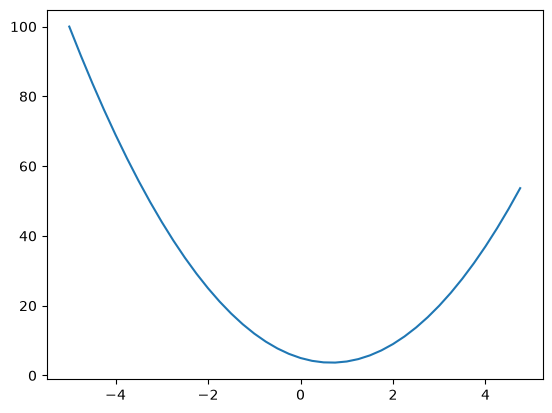

In [4]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

The same idea with several inputs: nudge `c` by a tiny amount `h` and measure how much `d` changes. That ratio is the slope of `d` with respect to `c`.

In [5]:
h = 0.0001
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c += h
d2 = a*b + c

print('d1:', d1)
print('d2:', d2)
print('slope:', (d2 - d1)/h)

d1: 4.0
d2: 4.0001
slope: 0.9999999999976694


## 2. The `value` class

`value` wraps a single number and remembers how it was created (its inputs and the operation). Each operation also stores a small `_backward` function that knows how to pass the gradient back to its inputs using the chain rule. `backward()` sorts the graph topologically and calls these functions from the output back to the inputs.

Gradients are accumulated with `+=` so that a value used in several places receives the gradient from every path.

In [6]:
class value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, value) else value(other)
        out = value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __radd__(self, other):  # handles: number + value
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, value) else value(other)
        out = value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other):  # handles: number * value
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = value(self.data ** other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out

    def __truediv__(self, other):  # a / b = a * b**-1
        return self * other**-1

    def __neg__(self):  # -a = a * -1
        return self * -1

    def __sub__(self, other):  # a - b = a + (-b)
        return self + (-other)

    def exp(self):
        x = self.data
        out = value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        # order all nodes so each one comes after its inputs
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        # walk from the output back to the inputs
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

## 3. Visualising the computation graph

Requires the `graphviz` Python package **and** the Graphviz program (`brew install graphviz` on macOS).

In [7]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{ %s | data: %.4f | grad: %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

## 4. Backpropagation on a small expression

Build `L = (a*b + c) * f`, run backprop, and look at the gradients.

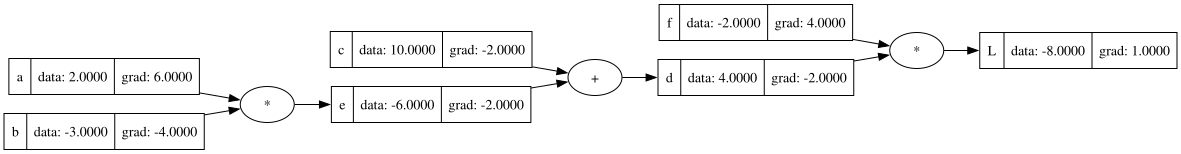

In [8]:
a = value(2.0, label='a')
b = value(-3.0, label='b')
c = value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = value(-2.0, label='f')
L = d*f; L.label = 'L'

L.backward()
draw_dot(L)

### The same gradients, worked out by hand

**Output node:** $\frac{dL}{dL} = 1$

**Multiplication** `L = d * f`: each input's gradient is the *other* input.
- $\frac{dL}{dd} = f = -2$
- $\frac{dL}{df} = d = 4$

**Addition** `d = e + c`: the local derivative is 1 for both inputs, so the gradient passes straight through.
- $\frac{dL}{dc} = \frac{dL}{dd} \cdot \frac{dd}{dc} = -2 \cdot 1 = -2$
- $\frac{dL}{de} = \frac{dL}{dd} \cdot \frac{dd}{de} = -2 \cdot 1 = -2$

**Multiplication** `e = a * b` (chain rule all the way back):
- $\frac{dL}{da} = \frac{dL}{de} \cdot \frac{de}{da} = -2 \cdot b = -2 \cdot (-3) = 6$
- $\frac{dL}{db} = \frac{dL}{de} \cdot \frac{de}{db} = -2 \cdot a = -2 \cdot 2 = -4$

In [9]:
for v in [a, b, c, f]:
    print(f"{v.label}: grad = {v.grad}")

a: grad = 6.0
b: grad = -4.0
c: grad = -2.0
f: grad = 4.0


### Numerical check

Nudge `a` by a tiny amount `h` and measure how much `L` changes. The result should be close to `a.grad` (6.0).

In [10]:
def numerical_grad_check():
    h = 0.001

    a = value(2.0, label='a')
    b = value(-3.0, label='b')
    c = value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L1 = L.data

    a = value(2.0 + h, label='a')  # nudge a
    b = value(-3.0, label='b')
    c = value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L2 = L.data

    print('numerical dL/da:', (L2 - L1)/h)

numerical_grad_check()

numerical dL/da: 6.000000000000227


### One step of gradient descent

Nudging every input a little in the direction of its gradient should make `L` go up (it starts at -8.0).

In [11]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a*b
d = e + c
L = d*f

print(L.data)

-7.286496


## 5. A single neuron

A neuron computes `tanh(x1*w1 + x2*w2 + b)`. The `tanh` squashes any input into the range -1 to 1:

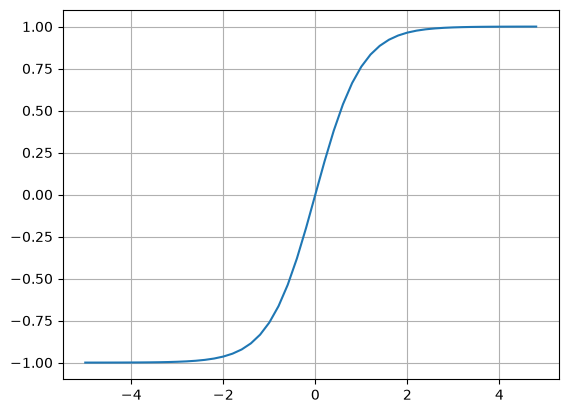

In [12]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)))
plt.grid();

### Manual backprop, one node at a time

Here each node's `_backward` is called by hand, from the output back to the inputs. This is exactly what `backward()` automates.

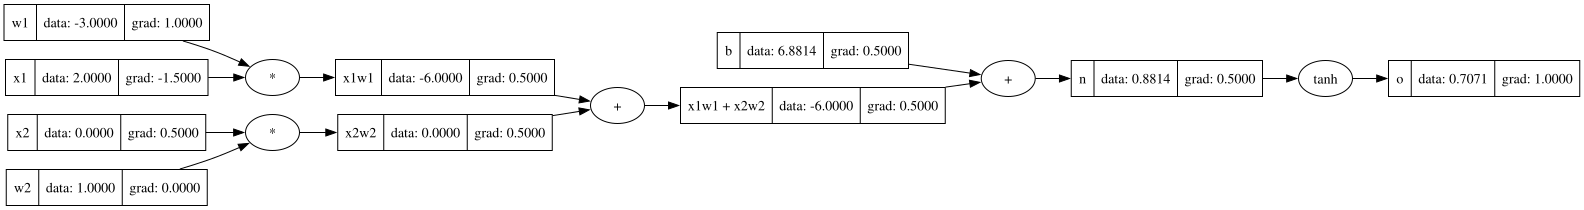

In [13]:
x1 = value(2.0, label='x1')
x2 = value(0.0, label='x2')
w1 = value(-3.0, label='w1')
w2 = value(1.0, label='w2')
b = value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.grad = 1.0
o._backward()
n._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()
draw_dot(o)

### Automatic backprop, with tanh built from smaller pieces

The graph is rebuilt from scratch (so the gradients start at zero) and `tanh` is written out as `(e^2n - 1) / (e^2n + 1)` using `exp`, division and subtraction. The gradients come out the same as above, which shows the building blocks compose correctly.

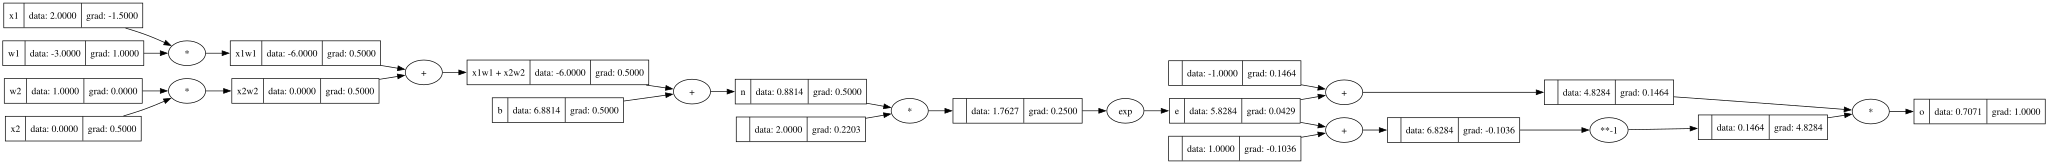

In [14]:
x1 = value(2.0, label='x1')
x2 = value(0.0, label='x2')
w1 = value(-3.0, label='w1')
w2 = value(1.0, label='w2')
b = value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
e = (2*n).exp(); e.label = 'e'
o = (e - 1) / (e + 1); o.label = 'o'

o.backward()
draw_dot(o)

## 6. Checking against PyTorch

The same neuron in PyTorch. The output and gradients should match the micrograd results above.

In [15]:
import torch

x1 = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)
x2 = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
w1 = torch.tensor(-3.0, dtype=torch.float64, requires_grad=True)
w2 = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
b = torch.tensor(6.8813735870195432, dtype=torch.float64, requires_grad=True)

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)
o.backward()

print(o.data.item())
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071067811865476
x2 0.49999999999999994
w2 0.0
x1 -1.4999999999999998
w1 0.9999999999999999


## 7. A multi-layer perceptron (MLP)

`Neuron` → `Layer` (a list of neurons) → `MLP` (a list of layers). Each class exposes `parameters()` so the training loop can update every weight and bias.

In [16]:
class Neuron:
    def __init__(self, nin):
        self.w = [value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = value(random.uniform(-1, 1))

    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        return act.tanh()

    def parameters(self):
        return self.w + [self.b]


class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [neuron(x) for neuron in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]


class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

A network with 3 inputs, two hidden layers of 4 neurons, and 1 output. The number of inputs must match the length of each example.

In [17]:
x = [2.0, 3.0, -1.0]
model = MLP(3, [4, 4, 1])
print('parameters:', len(model.parameters()))
model(x)

parameters: 41


value(data=0.6994093620224068)

### Training

A tiny dataset of 4 examples with target outputs of +1 or -1. Each step: forward pass, compute the squared-error loss, reset gradients to zero, backprop, and nudge every parameter against its gradient.

In [18]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]  # desired targets

In [19]:
losses = []
for k in range(20):
    # forward pass
    ypred = [model(x) for x in xs]
    loss = sum((yout - ygt)**2 for yout, ygt in zip(ypred, ys))

    # backward pass (reset gradients first, since they accumulate with +=)
    for p in model.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in model.parameters():
        p.data += -0.05 * p.grad

    losses.append(loss.data)
    print(k, loss.data)

0 5.230517512042234
1 2.704689050764245
2 1.846023725231498
3 1.1774870087919076
4 0.8217294550832637
5 0.5957215587693914
6 0.4311579409163274
7 0.3468314917603138
8 0.28903713992681357
9 0.2460506558393819
10 0.21309389813936697
11 0.18718814718937843
12 0.16638755353165707
13 0.14937997337031503
14 0.1352548466184191
15 0.12336389545940186
16 0.11323493741060496
17 0.1045170091877125
18 0.09694449026136834
19 0.09031307448189846


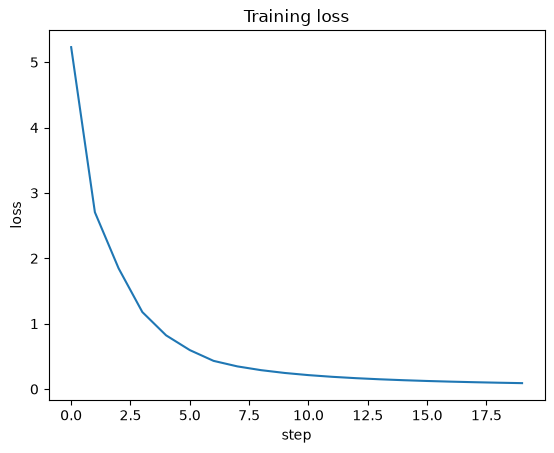

In [20]:
plt.plot(losses)
plt.xlabel('step')
plt.ylabel('loss')
plt.title('Training loss');

In [21]:
print('targets:    ', ys)
print('predictions:', [round(yp.data, 3) for yp in ypred])

targets:     [1.0, -1.0, -1.0, 1.0]
predictions: [0.836, -0.906, -0.807, 0.867]


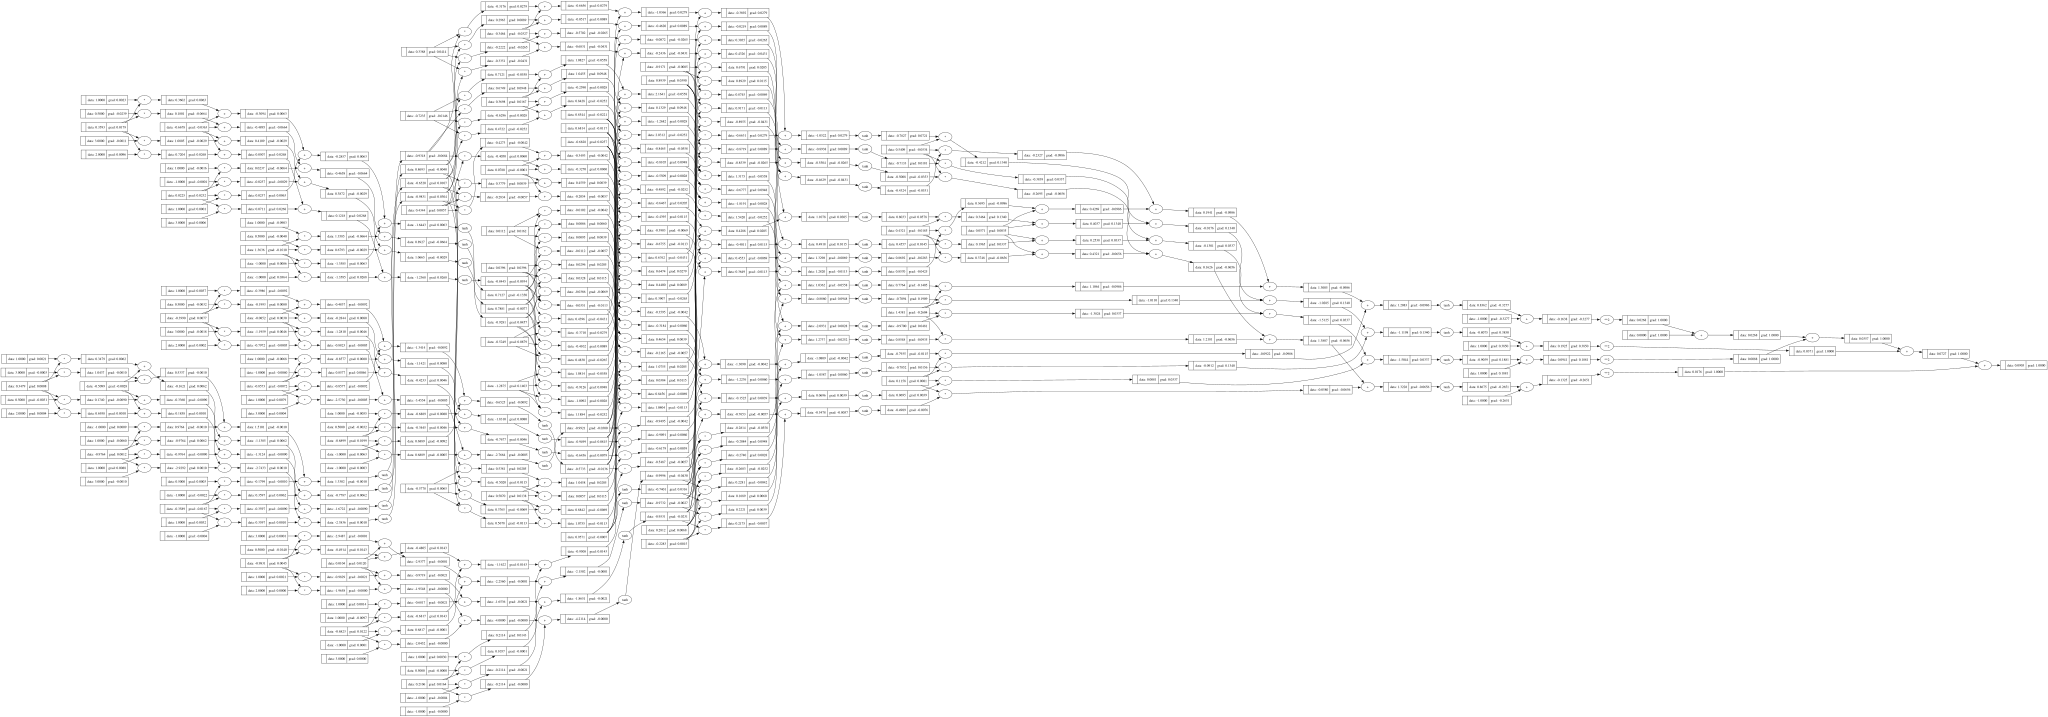

In [22]:
draw_dot(loss)